# Phase 2 — Baseline MiniLM Retrieval (validation only)
Viewer over the outputs of `python scripts/run_baseline.py`. **Nothing is computed or invented here**:
if the report is missing, the notebook says so. `test.tsv` is never used in this phase.

In [1]:
import sys
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "base.yaml").is_file())
sys.path.insert(0, str(root))
from src.config import load_config
from src.data_io import read_jsonl
from src.utils import read_json
cfg = load_config("configs/baseline.yaml", root=root)
reports, proc = cfg["_abs"]["reports_dir"], cfg["_abs"]["processed_dir"]
rp = reports / "baseline_val_metrics.json"
HAVE = rp.is_file()
print("baseline report found:" , HAVE)
if not HAVE:
    print("Run `python scripts/run_baseline.py` first, then re-run this notebook.")
else:
    rep = read_json(rp); print("status:", rep["status"], "| model:", rep["model"]["model_name"], "@", rep["model"]["resolved_revision"])

baseline report found: True
status: PASS | model: sentence-transformers/all-MiniLM-L6-v2 @ 1110a243fdf4706b3f48f1d95db1a4f5529b4d41


## 1. Validation metrics (baseline)

In [3]:
if HAVE:
    display(pd.Series(rep["metrics"], name="baseline (val)").to_frame().round(4))
    display(pd.Series(rep["eval_setup"]).to_frame("value"))

,baseline (val)
map@10,0.6398
mrr@10,0.6536
ndcg@10,0.6816
precision@10,0.0852
recall@1,0.5329
recall@10,0.7932
recall@5,0.7634


,value
candidate_corpus_size,5183
n_judgments,177
n_queries,162
note,Metrics compare against sparse known positives...
queries_missing_from_run,[]
retrieval_top_k,100


## 2. Integrity checks (cosine = inner product, index/ID alignment, reproducibility)

In [4]:
if HAVE: display(pd.Series(rep["checks"], name="value").to_frame())

,value
baseline_metrics_reproduced_on_rerun,True
doc_index_mapping_consistent,True
ip_equals_cosine,True
ip_vs_numpy_dot_max_abs_diff,0.0
ip_vs_sklearn_cosine_max_abs_diff,0.0
reencode_reproduces_cache,True
reencode_sample_max_abs_diff_vs_cache,0.0
reloaded_index_equals_in_memory_results,True
scores_sorted_descending,True
unit_norm_max_deviation,0.0


## 3. Truncation (exact, from the MiniLM tokenizer), latency and memory

In [5]:
if HAVE:
    print("truncation:", rep["truncation"])
    print("timing_s:", rep["timing_s"])
    print("single-query latency (ms):", rep["latency_single_query"])
    print("memory:", rep["memory_mb"])

truncation: {'fraction_truncated': 0.7102, 'max_seq_length': 256, 'n_texts': 5183, 'n_truncated': 3681, 'token_length_max': 1939, 'token_length_median': 316.0, 'token_length_p95': 567.8999999999996}
timing_s: {'encode_documents': 275.7357989999998, 'encode_val_queries_batch': 1.4150852999998733, 'model_load': 431.7677813}
single-query latency (ms): {'encode_ms': {'mean': 12.725045283026267, 'p50': 12.667200000123557, 'p95': 15.238469999917468}, 'faiss_search_ms': {'mean': 0.8486276729445594, 'p50': 0.8508999999321532, 'p95': 1.1427300000605098}, 'n_timed_queries': 159}
memory: {'note': 'RSS sampled at stage boundaries, not a true peak.', 'peak_rss_observed': 324.0}


## 4. Per-query nDCG@10 distribution and failure cases

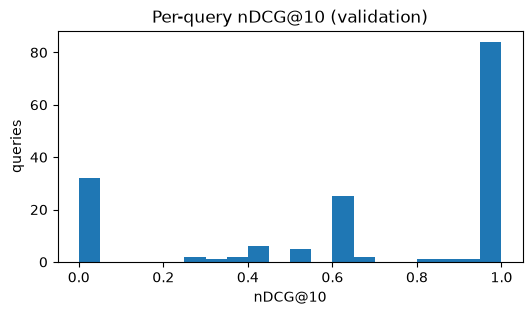

queries with no positive in top 10: 32 of 162

Query 610: Increased flux of microbial products suppresses immune responses.
  judged positive: ['Compromised intestinal epithelial barrier induces adaptive immune comp']
  top-3 retrieved: [('32454714', 0.597, 'Role of gut commensal microflora in the development of '), ('21439293', 0.582, 'Beyond pattern recognition: five immune checkpoints for'), ('20148808', 0.562, 'Microbiome-driven allergic lung inflammation is amelior')]
  (retrieved docs may be relevant but unjudged: qrels are sparse)

Query 1138: TRAP+ osteoclasts regulate mature osteoblast maintenance.
  judged positive: ['PDGF-BB secreted by preosteoclasts induces angiogenesis during couplin']
  top-3 retrieved: [('39776978', 0.558, 'Advances in osteoclast biology: old findings and new in'), ('24356383', 0.533, 'Reduced osteoblastic population and defective mineraliz'), ('12130067', 0.53, 'Osteoclasts promote the formation of hematopoietic stem')]
  (retrieved docs may be relevan

In [6]:
if HAVE:
    pq = pd.read_csv(reports / "baseline_val_per_query.csv", dtype={"query_id": str})
    plt.figure(figsize=(6, 3)); plt.hist(pq["ndcg@10"], bins=20); plt.title("Per-query nDCG@10 (validation)"); plt.xlabel("nDCG@10"); plt.ylabel("queries"); plt.show()
    print("queries with no positive in top 10:", int((pq["recall@10"] == 0).sum()), "of", len(pq))
    docs = {d["_id"]: d["title"] for d in read_jsonl(proc / "corpus_processed.jsonl")}
    qtext = {r["_id"]: r["text"] for r in read_jsonl(proc / "queries_processed.jsonl")}
    run = read_json(reports / "baseline_val_run_top100.json")
    from src.data_io import read_qrels
    pos = {}
    for q, d, _ in read_qrels(proc / "val_qrels.tsv"): pos.setdefault(q, set()).add(d)
    for q in pq.sort_values("ndcg@10").head(5)["query_id"]:
        print(f"\nQuery {q}: {qtext[q]}")
        print("  judged positive:", [docs[d][:70] for d in pos[q]])
        print("  top-3 retrieved:", [(d, round(s, 3), docs[d][:55]) for d, s in run[q][:3]])
        print("  (retrieved docs may be relevant but unjudged: qrels are sparse)")

## 5. Caveats
- Metrics are relative to sparse, positive-only judgments; an unjudged retrieved paper is not necessarily irrelevant.
- Similarity scores are cosine similarities, not probabilities of factual correctness.
- Latency/memory were measured on the machine that ran the script; they are not portable benchmarks.